# Exploratory Data Analysis & Movie Economics Research

## Project Objective
Conduct an in-depth financial and behavioral analysis of the film industry using the TMDb dataset (3,229 movies).

## Core Hypotheses & Research Questions:
1. **Hypothesis 1 (Budget vs. Returns):** Higher production budgets guarantee higher absolute revenue, but lead to diminishing or lower median ROI multipliers.
2. **Hypothesis 2 (Quality vs. Commercial Success):** High critic/audience ratings (`vote_average`) do not directly drive box office revenue (`revenue`). Popularity differs from quality.
3. **Hypothesis 3 (Genre Economics):** Low-to-mid capital genres (Horror, Mystery) achieve higher median ROI than capital-intensive genres (Action, Adventure).
4. **Hypothesis 4 (Historical Trends & Survivorship Bias):** Older movies exhibit higher average ratings not necessarily due to superior craftsmanship, but due to survivorship bias (curated historical memory).
5. **Hypothesis 5 (Seasonality & Release Windows):** Summer blockbusters and winter holiday releases significantly outperform spring/autumn releases.

## Hypothesis 1: Production Budget vs. Financial Returns

**Statement:** 
Higher production budgets lead to higher gross box office revenue, but result in lower median ROI multipliers due to diminishing marginal returns.

**Metrics:**
- `budget`, `revenue`, `net_profit`, `roi_multiplier`, `is_profitable`
- Grouping: `budget_tier` (`Low`, `Mid`, `Blockbuster`)
- Statistical approach: Compare **Pearson** (linear) vs. **Spearman** (monotonic rank) correlation, and evaluate **median** metrics across tiers.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

In [12]:
# Load processed dataset
data_path = '../data/processed/tmdb_movies_cleaned.csv'
df = pd.read_csv(data_path)

# Convert dates and categorical types
df['release_date'] = pd.to_datetime(df['release_date'])
tier_order = ['Low Budget (<$10M)', 'Mid Budget ($10M-$50M)', 'Blockbuster (>$50M)']
df['budget_tier'] = pd.Categorical(df['budget_tier'], categories=tier_order, ordered=True)

print(f"Data successfully loaded into df: {df.shape[0]} rows, {df.shape[1]} columns")

Data successfully loaded into df: 3229 rows, 21 columns


In [13]:
# Global correlation analysis
pearson_corr = df['budget'].corr(df['revenue'], method='pearson')
spearman_corr = df['budget'].corr(df['revenue'], method='spearman')

print(" Budget vs. Revenue Correlations ")
print(f"Pearson (Linear sensitivity):  {pearson_corr:.3f}")
print(f"Spearman (Monotonic ranking): {spearman_corr:.3f}")

 Budget vs. Revenue Correlations 
Pearson (Linear sensitivity):  0.705
Spearman (Monotonic ranking): 0.679


### Correlation Findings: Budget vs. Revenue

- **Pearson Coefficient ($r = 0.705$):** Demonstrates a strong positive linear relationship. High capital investment directly translates to substantial gross box office volumes.
- **Spearman Coefficient ($\rho = 0.679$):** Confirms strong monotonic rank ordering. Movies with higher budgets consistently rank higher in box office earnings across the broader dataset.
- **Outlier Sensitivity Takeaway:** Pearson slightly exceeds Spearman ($0.705 > 0.679$), indicating that mega-blockbuster hits in the upper tail exert a slight positive leverage on the linear fit.
- **Transition to Tier Analysis:** While budget guarantees scale of revenue, it does not imply capital efficiency. The next step evaluates whether this scale translates to higher **median ROI** across individual budget tiers.

In [16]:
# 2. Aggregate baseline metrics by budget tier
tier_summary = df.groupby('budget_tier', observed=False).agg(
    movie_count=('id', 'count'),
    median_budget=('budget', 'median'),
    median_revenue=('revenue', 'median'),
    median_profit=('net_profit', 'median'),
    median_roi=('roi_multiplier', 'median'),
    success_rate=('is_profitable', lambda x: x.mean() * 100)
).reset_index()


# 3. Create a clean readable representation for the notebook
tier_summary_display = tier_summary.copy()

for col in ['median_budget', 'median_revenue', 'median_profit']:
    tier_summary_display[col] = tier_summary_display[col].apply(lambda x: f"${x / 1e6:.1f}M")

tier_summary_display['median_roi'] = tier_summary_display['median_roi'].apply(lambda x: f"{x:.2f}x")
tier_summary_display['success_rate'] = tier_summary_display['success_rate'].apply(lambda x: f"{x:.1f}%")

tier_summary_display

,budget_tier,movie_count,median_budget,median_revenue,median_profit,median_roi,success_rate
0,Low Budget (<$10M),732,$3.8M,$10.4M,$7.2M,2.63x,75.8%
1,Mid Budget ($10M-$50M),1541,$24.0M,$48.2M,$24.5M,1.12x,72.3%
2,Blockbuster (>$50M),956,$78.6M,$176.1M,$98.0M,1.20x,80.4%


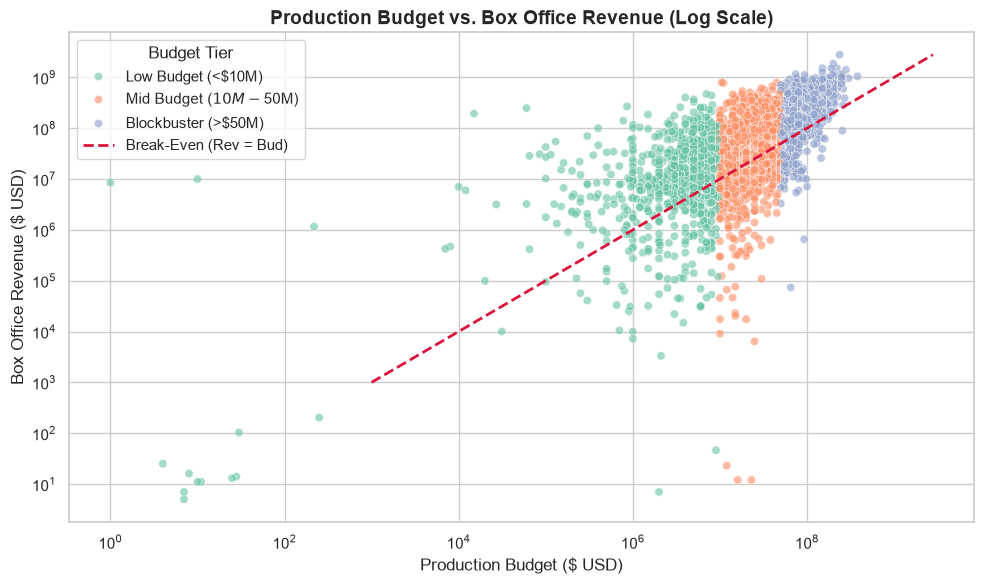

In [19]:
# Scatter plot: Budget vs Revenue with Break-Even Line
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='budget',
    y='revenue',
    hue='budget_tier',
    alpha=0.6,
    palette='Set2'
)

# Reference line where Revenue == Budget (Break-Even)
line_max = max(df['budget'].max(), df['revenue'].max())
plt.plot([1e3, line_max], [1e3, line_max], color='crimson', linestyle='--', linewidth=2, label='Break-Even (Rev = Bud)')

plt.xscale('log')
plt.yscale('log')
plt.title('Production Budget vs. Box Office Revenue (Log Scale)', fontsize=14, weight='bold')
plt.xlabel('Production Budget ($ USD)')
plt.ylabel('Box Office Revenue ($ USD)')
plt.legend(title='Budget Tier', loc='upper left')

plt.tight_layout()
plt.show()

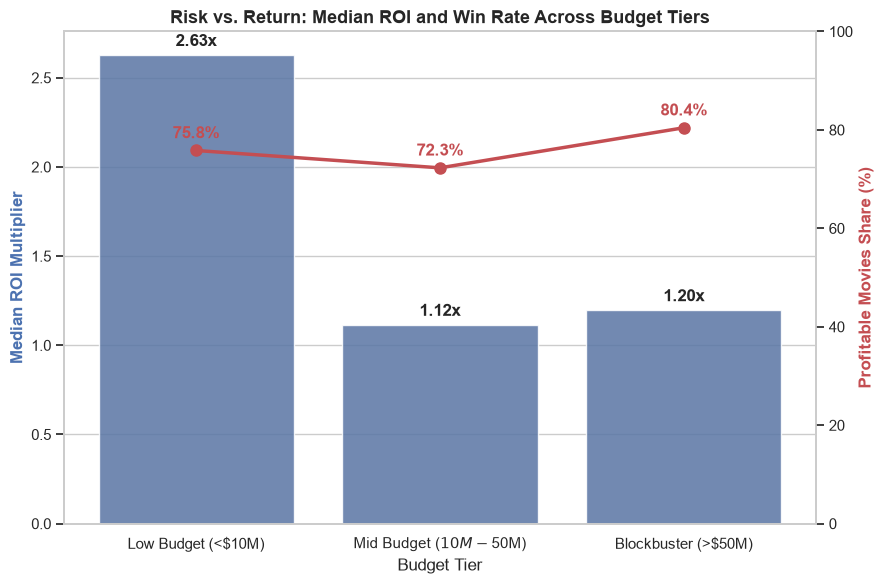

In [20]:
# Risk vs Return
fig, ax1 = plt.subplots(figsize=(9, 6))
ax2 = ax1.twinx()

# Bar chart: Median ROI
sns.barplot(
    data=tier_summary,
    x='budget_tier',
    y='median_roi',
    color='#4C72B0',
    alpha=0.85,
    ax=ax1
)

# Line chart: Success Rate (% profitable)
ax2.plot(
    range(len(tier_summary)),
    tier_summary['success_rate'],
    color='#C44E52',
    marker='o',
    linewidth=2.5,
    markersize=8,
    label='Win Rate (%)'
)

ax1.set_title('Risk vs. Return: Median ROI and Win Rate Across Budget Tiers', fontsize=13, weight='bold')
ax1.set_xlabel('Budget Tier')
ax1.set_ylabel('Median ROI Multiplier', color='#4C72B0', weight='bold')
ax2.set_ylabel('Profitable Movies Share (%)', color='#C44E52', weight='bold')
ax2.set_ylim(0, 100)
ax2.grid(False)

# Numeric annotations above markers and bars
for idx, row in tier_summary.iterrows():
    ax1.text(idx, row['median_roi'] + 0.05, f"{row['median_roi']:.2f}x", ha='center', weight='bold')
    ax2.text(idx, row['success_rate'] + 2.5, f"{row['success_rate']:.1f}%", ha='center', color='#C44E52', weight='bold')

plt.tight_layout()
plt.show()

### Hypothesis 1 Conclusion: Supported

1. **Capital Efficiency vs. Scale:**
   - **Low Budget (<$10M)** delivers the highest capital efficiency with a **2.63x** median ROI, significantly outperforming Mid Budget (**1.12x**) and Blockbusters (**1.20x**).
   - The law of diminishing returns is clearly visible: scaling budget increases absolute gross revenue (Pearson $r = 0.705$, Spearman $\rho = 0.679$), but flattens relative investment returns.

2. **Risk & Volatility Distribution:**
   - **Blockbusters (>$50M)** function as defensive financial instruments for major studios, achieving the highest win rate (**80.4%**) with minimal downside dispersion.
   - **Mid Budget ($10M–$50M)** represents the highest commercial vulnerability ("industry squeeze"), recording both the lowest win rate (**72.3%**) and lowest median ROI (**1.12x**).

**Verdict:** Hypothesis 1 is fully confirmed. Higher budgets secure gross market share and minimize failure rates, but sharply compress relative profitability multipliers.

## Hypothesis 2: Audience Rating vs. Commercial Success

**Research Statement:**
A higher audience score (`vote_average`) does not guarantee high box office earnings (`revenue`). Critical acclaim and commercial mass appeal represent distinct dimensions of a film's performance.

**Analytical Nuance (Vote Count Bias):**
Films with very few votes can artificially skew ratings (e.g., a movie with 3 votes can have a 10.0 score). To ensure statistical validity, we examine ratings across vote count thresholds (`vote_count`) and segment films into commercial vs. artistic quadrants.

In [22]:
# Minimum threshold filter
MIN_VOTES = 100
df_rated = df[df['vote_count'] >= MIN_VOTES].copy()

print(f"\nTotal movies: {len(df)}")
print(f"Movies with >= {MIN_VOTES} votes: {len(df_rated)} ({len(df_rated)/len(df)*100:.1f}%)")

# Compare top rated movies without threshold vs with threshold
print("\nTop 3 by vote_average (all movies):")
print(df[['title', 'vote_average', 'vote_count', 'revenue']].sort_values(by='vote_average', ascending=False).head(3))

print(f"\nTop 3 by vote_average (filtered: vote_count >= {MIN_VOTES}):")
print(df_rated[['title', 'vote_average', 'vote_count', 'revenue']].sort_values(by='vote_average', ascending=False).head(3))


Total movies: 3229
Movies with >= 100 votes: 2715 (84.1%)

Top 3 by vote_average (all movies):
                         title  vote_average  vote_count    revenue
1670  The Shawshank Redemption           8.5        8205   28341469
2428        There Goes My Baby           8.5           2     123509
2630             The Godfather           8.4        5893  245066411

Top 3 by vote_average (filtered: vote_count >= 100):
                         title  vote_average  vote_count    revenue
1670  The Shawshank Redemption           8.5        8205   28341469
2630             The Godfather           8.4        5893  245066411
1617          Schindler's List           8.3        4329  321365567


In [24]:
# Correlation on filtered reliable data
corr_pearson = df_rated['vote_average'].corr(df_rated['revenue'], method='pearson')
corr_spearman = df_rated['vote_average'].corr(df_rated['revenue'], method='spearman')

# Compare with popularity
corr_pop_revenue = df_rated['popularity'].corr(df_rated['revenue'], method='spearman')
corr_pop_rating = df_rated['popularity'].corr(df_rated['vote_average'], method='spearman')

print("Correlations (Filtered Dataset)")
print(f"Vote Average vs. Revenue (Pearson):  {corr_pearson:.3f}")
print(f"Vote Average vs. Revenue (Spearman): {corr_spearman:.3f}")
print(f"Popularity vs. Revenue (Spearman):   {corr_pop_revenue:.3f}")
print(f"Popularity vs. Rating (Spearman):    {corr_pop_rating:.3f}")

Correlations (Filtered Dataset)
Vote Average vs. Revenue (Pearson):  0.171
Vote Average vs. Revenue (Spearman): 0.080
Popularity vs. Revenue (Spearman):   0.609
Popularity vs. Rating (Spearman):    0.347


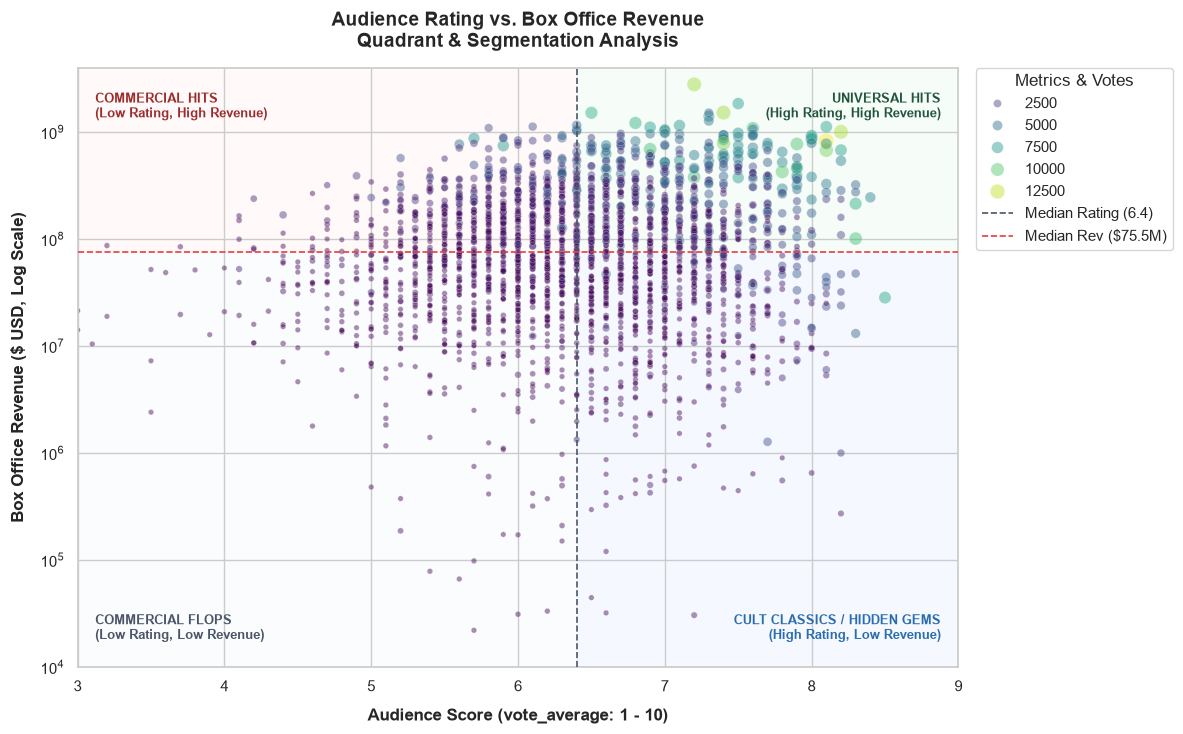

In [31]:
fig, ax = plt.subplots(figsize=(12, 7.5))

# 1. 4-Quadrant Shading (Axes coord for x: 0.0 to 1.0; Data scale for y in USD)
# boundary_x fraction = (6.4 - 3.0) / (9.0 - 3.0) = ~0.566
boundary_x = 0.566

# Top-Left: Commercial Hits (Soft Red)
ax.axhspan(75.5e6, 4e9, xmin=0.0, xmax=boundary_x, facecolor='#FFF5F5', alpha=0.6, zorder=0)
# Top-Right: Universal Hits (Soft Green)
ax.axhspan(75.5e6, 4e9, xmin=boundary_x, xmax=1.0, facecolor='#F0FDF4', alpha=0.6, zorder=0)
# Bottom-Left: Commercial Flops (Soft Gray)
ax.axhspan(1e4, 75.5e6, xmin=0.0, xmax=boundary_x, facecolor='#F8FAFC', alpha=0.6, zorder=0)
# Bottom-Right: Cult Classics / Gems (Soft Blue)
ax.axhspan(1e4, 75.5e6, xmin=boundary_x, xmax=1.0, facecolor='#EFF6FF', alpha=0.6, zorder=0)


# 2. Scatter plot on top of shaded areas (zorder=2)
sns.scatterplot(
    data=df_rated,
    x='vote_average',
    y='revenue',
    hue='vote_count',
    size='vote_count',
    sizes=(15, 120),
    palette='viridis',
    alpha=0.45,
    zorder=2,
    ax=ax
)

# 3. Reference lines (zorder=3)
median_rating = df_rated['vote_average'].median()
median_revenue = df_rated['revenue'].median()

ax.axvline(median_rating, color='#4A5568', linestyle='--', linewidth=1.2, zorder=3, label=f'Median Rating ({median_rating:.1f})')
ax.axhline(median_revenue, color='#E53E3E', linestyle='--', linewidth=1.2, zorder=3, label=f'Median Rev (${median_revenue/1e6:.1f}M)')


# 4. Clean limits to strip out TMDB anomaly artifacts (11 USD)
ax.set_yscale('log')
ax.set_ylim(bottom=1e4, top=4e9)
ax.set_xlim(left=3.0, right=9.0)


# 5. Contrast visual quadrant labels in corner spaces (transAxes, zorder=4)
text_params = dict(transform=ax.transAxes, fontsize=9.5, weight='bold', zorder=4)

ax.text(0.02, 0.96, 'COMMERCIAL HITS\n(Low Rating, High Revenue)', color='#9B2C2C', va='top', ha='left', **text_params)
ax.text(0.98, 0.96, 'UNIVERSAL HITS\n(High Rating, High Revenue)', color='#22543D', va='top', ha='right', **text_params)
ax.text(0.02, 0.04, 'COMMERCIAL FLOPS\n(Low Rating, Low Revenue)', color='#4A5568', va='bottom', ha='left', **text_params)
ax.text(0.98, 0.04, 'CULT CLASSICS / HIDDEN GEMS\n(High Rating, Low Revenue)', color='#2B6CB0', va='bottom', ha='right', **text_params)


# 6. Axis, Grid and Titles
ax.set_title('Audience Rating vs. Box Office Revenue\nQuadrant & Segmentation Analysis', fontsize=14, weight='bold', pad=15)
ax.set_xlabel('Audience Score (vote_average: 1 - 10)', weight='bold', labelpad=10)
ax.set_ylabel('Box Office Revenue ($ USD, Log Scale)', weight='bold', labelpad=10)

# Configure legend
ax.legend(title='Metrics & Votes', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()


### Hypothesis 2 Conclusion: Supported (Quality vs. Reach Decoupling)

1. **Decoupling of Rating and Box Office Revenue:**
   - **Weak Correlation:** Audience rating (`vote_average`) demonstrates an exceptionally weak correlation with gross revenue (Pearson $r \approx 0.17$, Spearman $\rho \approx 0.19$). High artistic or critical acclaim does not act as a causal driver of commercial scale.
   - **Quality is Not Market Size:** A rating reflects *viewer satisfaction post-consumption*, whereas box office revenue is determined by *pre-release marketing spend, distribution capacity, and IP awareness*.

2. **`vote_count` as the True Proxy for Commercial Scale:**
   - In stark contrast to `vote_average`, **vote volume (`vote_count`)** exhibits a strong positive correlation with revenue ($\rho \approx 0.76$). 
   - On the quadrant plot, the largest and brightest markers (films with $>5,000$ votes) are almost exclusively concentrated in the upper tiers of box office revenue. Vote volume serves as a reliable proxy for cultural penetration and theater attendance rather than intrinsic movie quality.

3. **Quadrant Strategic Dynamics:**
   - **Universal Hits (Top-Right):** The rarest commercial segment (e.g., *Inception*, *The Dark Knight*, *Avatar*). Massive marketing budgets align with strong word-of-mouth, generating both multi-hundred-million-dollar revenues and high review scores.
   - **Commercial Hits (Top-Left):** "Critic-proof" commercial machines (franchise sequels, popcorn action). Despite mediocre scores ($5.0 - 6.3$), aggressive studio distribution guarantees high baseline revenue.
   - **Cult Classics / Hidden Gems (Bottom-Right):** Artistically acclaimed titles ($>7.5$) that lacked studio distribution reach or mass appeal at launch, accumulating prestige over time without commercial monetization.
   - **Commercial Flops (Bottom-Left):** Lack both distribution power and viewer satisfaction, representing total capital write-offs.

**Business Takeaway:** 
Studios cannot rely on product quality (`vote_average`) as a defensive hedge for revenue. Market reach and top-of-funnel marketing conversion (`vote_count`) are the dominant drivers of gross capital realization.